In [1]:
import autograd.numpy as np

In [2]:
from MLRPlotting import static_plotter
# import custom plotting tools
static_plotter = static_plotter.Visualizer()

# Exercise 2

In [3]:
# standard normalization function - with nan checker / filler in-er
def standard_normalizer(x):    
    # compute the mean and standard deviation of the input
    x_means = np.nanmean(x,axis = 1)[:,np.newaxis]
    x_stds = np.nanstd(x,axis = 1)[:,np.newaxis]   

    # check to make sure that x_stds > small threshold, for those not
    # divide by 1 instead of original standard deviation
    ind = np.argwhere(x_stds < 10**(-2))
    if len(ind) > 0:
        ind = [v[0] for v in ind] # Just keep the row index
        adjust = np.zeros((x_stds.shape))
        adjust[ind] = 1.0
        x_stds += adjust

    # fill in any nan values with means 
    ind = np.argwhere(np.isnan(x) == True)
    for i in ind:
        x[i[0],i[1]] = x_means[i[0]]

    # create standard normalizer function
    normalizer = lambda data: (data - x_means)/x_stds

    # create inverse standard normalizer
    inverse_normalizer = lambda data: data*x_stds + x_means

    # return normalizer 
    return normalizer,inverse_normalizer

In [12]:
# data input
csvname = 'spambase_data.csv'
data = np.loadtxt(csvname,delimiter = ',')

# get input and output of dataset
x = data[:-1,:]
y = data[-1:,:] 
normalizer,inverse_normalizer = standard_normalizer(x)
x = normalizer(x)

In [13]:
import autograd.numpy as np
# compute linear combination of input points
def model(x,w):
    a = w[0] + np.dot(x.T,w[1:])
    return a.T

# an implementation of the softmax cost
def softmax(w):    
    cost = np.sum(np.log(1 + np.exp(-y*model(x,w))))
    return cost/float(np.size(y))

# an implementation of the perceptron cost
def perceptron(w):
    cost = np.sum(np.maximum(0, -y*model(x, w)))
    return cost/float(np.size(y))

# import automatic differentiator to compute gradient module
from autograd import grad 

# gradient descent function - inputs: g (input function), alpha (steplength parameter), max_its (maximum number of iterations), w (initialization)
def gradient_descent(g,alpha,max_its,w):
    # compute gradient module using autograd
    gradient = grad(g)

    # run the gradient descent loop
    weight_history = [w]           # container for weight history
    cost_history = [g(w)]          # container for corresponding cost function history
    for k in range(max_its):
        # evaluate the gradient, store current weights and cost function value
        grad_eval = gradient(w)

        # take gradient descent step
        w = w - alpha*grad_eval
        
        # record weight and cost
        weight_history.append(w)
        cost_history.append(g(w))
    return weight_history, cost_history

# 2.1

In [14]:
# parameters for gradient descent
max_its = 1000
N = x.shape[0]
w = 0.1*np.random.randn(N+1,1)
alpha_percep = 0.1
weight_history_percep, cost_history_percep = gradient_descent(perceptron,alpha_percep,max_its,w)
alpha_softmax = 1
weight_history_softmax, cost_history_softmax = gradient_descent(softmax,alpha_softmax,max_its,w)

In [15]:
### miscounts ###
def miscount(w, x, y):
    preds = model(x, w)
    return np.sum(-y*preds<0)

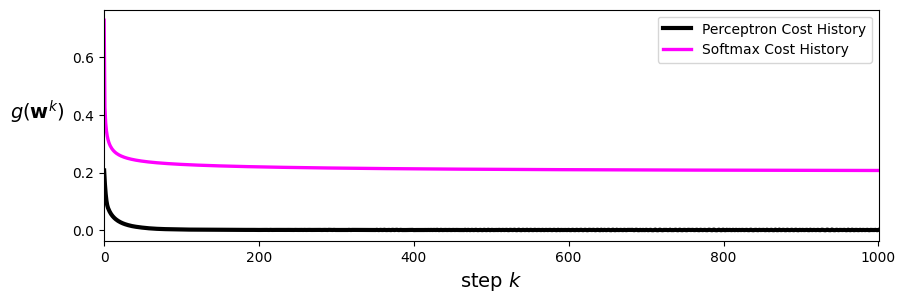

In [16]:
# plotting the cost histories
static_plotter.plot_cost_histories([cost_history_percep,cost_history_softmax],start=0,points=False,labels=[r'Perceptron Cost History',r'Softmax Cost History'])

Both cost functions decreases gradually and the softmax cost function decreases more.

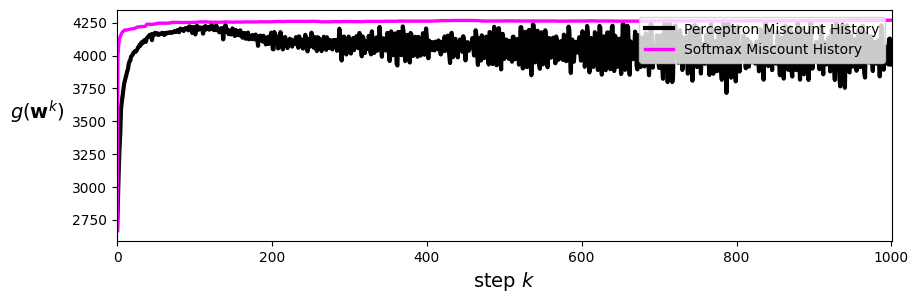

In [17]:
# plotting the miscount history
miscount_history_percep = [miscount(v,x,y) for v in weight_history_percep]	
miscount_history_softmax = [miscount(v,x,y) for v in weight_history_softmax]
static_plotter.plot_cost_histories([miscount_history_percep,miscount_history_softmax],start=0,points=False,labels=[r'Perceptron Miscount History',r'Softmax Miscount History'])

The number of misclassified points increases with the number of iteration even though the cost function is decreasing over the number of iterations.

# 2.2

In [18]:
# smallest miscount and corresponding cost for perceptron
min_miscount_percep = np.min(miscount_history_percep)
accuracy_percep = 1 - min_miscount_percep/float(y.shape[1])
print('Perceptron minimum miscount: ', min_miscount_percep)
print('Perceptron accuracy: ' , accuracy_percep)

# smallest miscount and corresponding cost for softmax
min_miscount_softmax = np.min(miscount_history_softmax)
accuracy_softmax = 1 - min_miscount_softmax/float(y.shape[1])
print('Softmax minimum miscount: ', min_miscount_softmax)
print('Softmax accuracy: ', accuracy_softmax)

Perceptron minimum miscount:  2669
Perceptron accuracy:  0.4199087154966311
Softmax minimum miscount:  2669
Softmax accuracy:  0.4199087154966311


# 2.3

In [19]:
# Best w for softmax
best_w_softmax = weight_history_softmax[np.argmin(miscount_history_softmax)]
print('Best w for softmax: \n', best_w_softmax)

Best w for softmax: 
 [[-0.02009398]
 [ 0.0909601 ]
 [-0.00426457]
 [ 0.14127348]
 [-0.03609308]
 [-0.00194886]
 [ 0.26066566]
 [-0.01769852]
 [ 0.1816664 ]
 [ 0.01519276]
 [-0.01120684]
 [-0.01852422]
 [-0.02738859]
 [-0.24487458]
 [ 0.09689755]
 [ 0.01140666]
 [ 0.00200067]
 [-0.12625476]
 [ 0.0085389 ]
 [-0.0593532 ]
 [-0.18943443]
 [ 0.07414493]
 [ 0.03378409]
 [-0.07901338]
 [-0.00982639]
 [-0.12587715]
 [ 0.00794085]
 [ 0.11216175]
 [ 0.06148157]
 [ 0.10600202]
 [ 0.05165275]
 [ 0.06250515]
 [-0.06019065]
 [ 0.00211291]
 [ 0.0530319 ]
 [ 0.01569664]
 [ 0.07922488]
 [-0.00115862]
 [-0.06604899]
 [ 0.04303857]
 [ 0.13089489]
 [-0.06149388]
 [ 0.00246989]
 [ 0.00047356]
 [ 0.04303667]
 [-0.09681503]
 [-0.04440792]
 [ 0.01793187]
 [ 0.13105461]
 [ 0.06272766]
 [-0.13291773]
 [-0.18591381]
 [ 0.09032938]
 [-0.05148674]
 [ 0.03633719]
 [ 0.14553762]
 [-0.09810127]
 [ 0.10769292]]


In [22]:
# confusion matrix for softmax
preds = model(x, best_w_softmax)
TP = np.sum((preds >= 0) & (y == 1))
TN = np.sum((preds <= 0) & (y == -1))
FP = np.sum((preds >= 0) & (y == -1))
FN = np.sum((preds <= 0) & (y == 1))

confusion_matrix = np.array([[TP, FP], [FN, TN]])
print('Confusion Matrix for Softmax:\n', confusion_matrix)

Confusion Matrix for Softmax:
 [[ 948 1067]
 [ 865 1721]]


In [21]:
preds

array([[ 0.1637846 , -0.20480515,  0.01529945, ..., -0.63638255,
         0.09471584, -0.78687589]])